In [5]:
import pandas as pd, re
from urllib.parse import urlparse

df = pd.read_csv("../data/phishing_site_urls.csv")
print(df.shape, df.columns.tolist())
print(df.Label.value_counts(normalize=True))
print(df.isna().sum())

# dedupe BEFORE splitting, otherwise same URL lands in train and test = leakage
df = df.drop_duplicates(subset="URL").reset_index(drop=True)
df["y"] = (df.Label == "bad").astype(int)

SUS = ["login", "verify", "bank", "secure", "account", "update", "signin", "paypal"]
IP_RE = re.compile(r"(\d{1,3}\.){3}\d{1,3}")

def extract(url):
    u = url if "://" in url else "http://" + url
    try:
        host = urlparse(u).netloc
    except ValueError:
        # malformed URL, fall back to a manual host grab
        host = u.split("://", 1)[1].split("/", 1)[0]
    return {
        "url_len": len(url),
        "host_len": len(host),
        "dots": url.count("."),
        "hyphens": url.count("-"),
        "has_at": int("@" in url),
        "has_ip": int(bool(IP_RE.search(host))),
        "https": int(url.lower().startswith("https")),
        "subdomains": max(host.count(".") - 1, 0),
        "digits": sum(c.isdigit() for c in url),
        "slashes": url.count("/"),
        "sus_words": sum(w in url.lower() for w in SUS),
    }

X = pd.DataFrame(df.URL.apply(extract).tolist())
y = df.y
print(X.shape)
X.head()

(549346, 2) ['URL', 'Label']
Label
good    0.715258
bad     0.284742
Name: proportion, dtype: float64
URL      0
Label    0
dtype: int64
(507195, 11)


,url_len,host_len,dots,hyphens,has_at,has_ip,https,subdomains,digits,slashes,sus_words
0,225,9,6,4,0,0,0,0,58,10,1
1,81,15,5,2,0,0,0,1,1,4,1
2,177,16,7,1,0,0,0,0,47,11,3
3,60,18,6,0,0,0,0,1,0,2,0
4,116,19,1,1,0,0,0,0,21,10,0


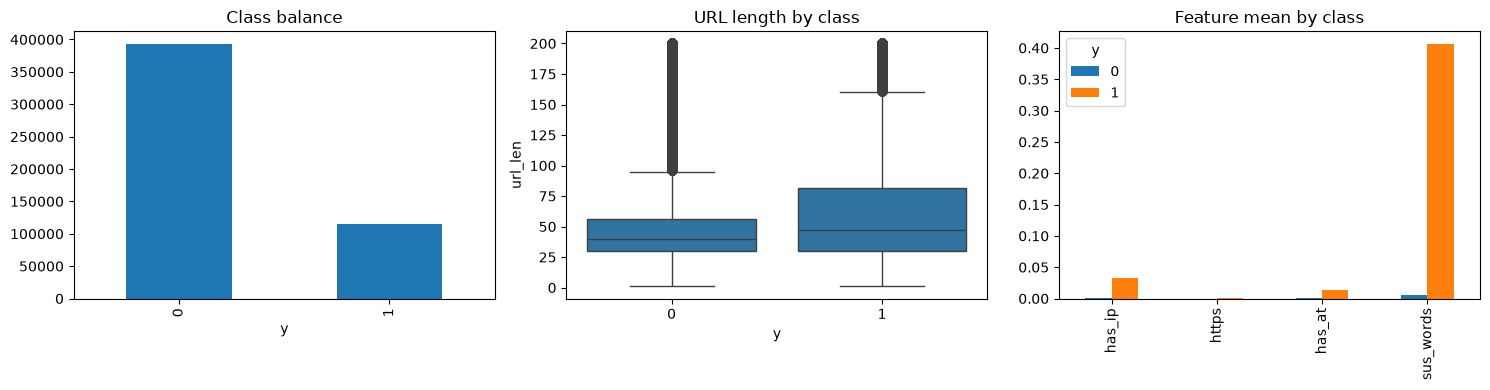

In [6]:
import matplotlib.pyplot as plt, seaborn as sns

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
y.value_counts().plot.bar(ax=ax[0], title="Class balance")
sns.boxplot(x=y, y=X.url_len.clip(upper=200), ax=ax[1]); ax[1].set_title("URL length by class")
X.groupby(y)[["has_ip", "https", "has_at", "sus_words"]].mean().T.plot.bar(ax=ax[2], title="Feature mean by class")
plt.tight_layout()
plt.savefig("eda.png", dpi=120)
plt.show()

In [7]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score
from xgboost import XGBClassifier

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "RF": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
    "XGB": XGBClassifier(n_estimators=300, max_depth=6, eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    cv_f1 = cross_val_score(m, Xtr, ytr, cv=cv, scoring="f1").mean()
    m.fit(Xtr, ytr)
    p = m.predict(Xte)
    pr, rc, f1, _ = precision_recall_fscore_support(yte, p, average="binary")
    rows.append(dict(model=name, acc=accuracy_score(yte, p), precision=pr, recall=rc, f1=f1, cv_f1=cv_f1))
    print("done", name)

results = pd.DataFrame(rows).sort_values("f1", ascending=False).round(4)
print(results.to_markdown(index=False))

done LogReg
done Tree
done RF
done XGB
| model   |    acc |   precision |   recall |     f1 |   cv_f1 |
|:--------|-------:|------------:|---------:|-------:|--------:|
| RF      | 0.9091 |      0.846  |   0.7292 | 0.7833 |  0.7797 |
| XGB     | 0.9048 |      0.8682 |   0.6811 | 0.7633 |  0.7633 |
| Tree    | 0.8723 |      0.8261 |   0.5487 | 0.6594 |  0.6631 |
| LogReg  | 0.8515 |      0.8996 |   0.3841 | 0.5383 |  0.5397 |


RF
[[75545  3034]
 [ 6191 16669]]
              precision    recall  f1-score   support

           0       0.92      0.96      0.94     78579
           1       0.85      0.73      0.78     22860

    accuracy                           0.91    101439
   macro avg       0.89      0.85      0.86    101439
weighted avg       0.91      0.91      0.91    101439



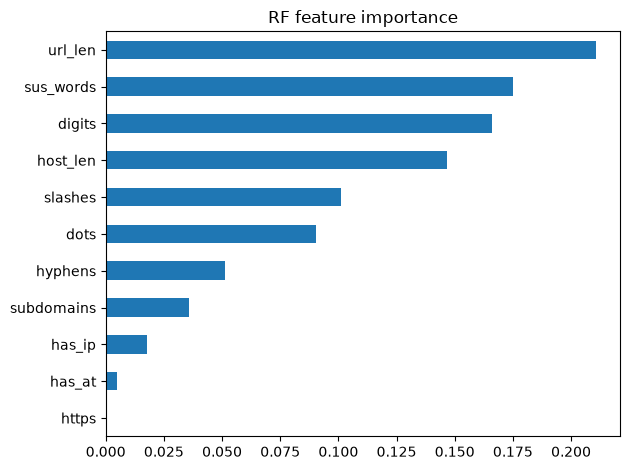

6191
488190    dl.dropboxusercontent.com/content_link/BqB1LhK...
109314            tsnwires.co.th/templates/kongoon/library/
495305                                       partyeazy.com/
109397                   theteesbar.com/pkginfo/mobile2016/
480459                   www.massage-ketsch.de/wp-includes/
39225              www.5financial.info/page/vote.php?pid=50
484061                               babax.esy.es/admin.php
480388                        omni-trust. com/Sparkasse.apk
8018      'www.jcsykes.co.uk/images/PHP/index.php?action...
120673          giftcard-sale.com/marriott/rewards/Marriott
116229                            shellyatwood.com/dat/docx
36479     fashion-diva.net/wp-content/uploads/2012/Truli...
23599                           bboline.3eeweb.com/bboline/
106335                       walterbrant.com/trustpass.html
124609           amisgourmet.com.br/Styles/mgs/es/index.php
114366          potbnb.com/dopbcp/alibaba/alibaba/index.php
487641                      cabanas

['../best_model.joblib']

In [8]:
import joblib, numpy as np

best_name = results.iloc[0].model
best = models[best_name]
pred = best.predict(Xte)
print(best_name)
print(confusion_matrix(yte, pred))
print(classification_report(yte, pred))

imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(title=f"{best_name} feature importance")
plt.tight_layout()
plt.savefig("importance.png", dpi=120)
plt.show()

# false negatives = phishing the model missed
fn = df.loc[Xte.index[((yte == 1) & (pred == 0)).values], "URL"]
print(len(fn))
print(fn.head(20).to_string())

joblib.dump(best, "../best_model.joblib", compress=3)

## Step 6: Thinking like a security person

### Results on the held-out test set (101,439 URLs)

| | Predicted good | Predicted phishing |
|---|---|---|
| **Actually good** | 75,545 | 3,034 (false alarms) |
| **Actually phishing** | 6,191 (missed) | 16,669 (caught) |

Best model: Random Forest. Precision 0.85, recall 0.73, F1 0.78, accuracy 91%.
5-fold CV F1 was 0.780 vs test F1 0.783, so the result is stable.

### Precision or recall?

Recall matters more here. A missed phishing URL (false negative) can lead to stolen
credentials, while a false alarm (false positive) only annoys the user. Our model
misses 27% of phishing, which is too high for a real security tool.

Precision still matters, because a tool that cries wolf gets ignored. Only about 3.9%
of good URLs were wrongly flagged (3,034 of 78,579), which is a reasonable trade-off.
Lowering the decision threshold below 0.5 would raise recall at the cost of more false
alarms. I did not tune this, so it is a possible next step.

### What do the missed phishing URLs (false negatives) have in common?

- Short, clean-looking URLs (e.g. `partyeazy.com/`) with no suspicious keywords
- Compromised legitimate sites (WordPress paths like `/wp-includes/`, `/images/index.php`)
- Links on trusted file-hosting domains (e.g. Dropbox)

URL text alone can't tell these apart from legit sites. Catching them would need
page content, domain age (WHOIS), or reputation data.

### Leakage and dataset checks

- Removed 42,151 exact duplicate URLs *before* splitting (549,346 -> 507,195), so the
  same URL can't appear in both train and test.
- No single feature dominates: importance is spread across url_len, sus_words, digits
  and host_len, and accuracy is 91%, not 99%. That suggests no obvious leakage.
- `https` is near zero for both classes, so this dataset mostly strips the scheme.
  The feature is useless here.
- Remaining limitation: I only removed exact duplicates. Different URLs from the
  same domain can still land in both train and test, which may inflate scores slightly.
- Dataset noise: some URLs have stray quotes or spaces. The good/bad URLs may also come
  from different sources, which could introduce bias.